# Case Study 05 — What Correlation Can and Cannot Tell You

**Pearson vs Spearman · outliers that create and destroy correlation · confounding and partial correlation ·
reverse causality · restriction of range · segment reversal · non-linear relationships with zero correlation ·
significance vs strength · spurious correlation in time series**

| | |
|---|---|
| **Domain** | Credit cards: spend growth strategy |
| **Stakeholder** | Head of Cards |
| **Difficulty** | Beginner |
| **Importance** | 🔴 MUST GO THROUGH |
| **Builds on** | Case 01 (descriptive statistics, CIs), Case 02 (tests, confounding preview) |
| **Data** | 6,000 cardholders; 36 months of portfolio totals |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py`.

**What you will learn**

1. What Pearson's r and Spearman's ρ measure, how to put a **confidence interval** on them, and what r² means.
2. How a handful of **outliers can create or destroy** a correlation.
3. Why a correlation between X and Y can come from a **third variable** (confounding), from **Y causing X** (reverse
   causality), or can **flip sign** inside segments.
4. Why **zero correlation does not mean no relationship**.
5. Why two **trending time series** almost always look correlated.
6. **What you may and may not claim** from a correlation, and the exact language to use.

## Section 1 — Business context

You are a data scientist in the **Cards Analytics** team of a retail bank. The Head of Cards is preparing the
growth plan and has three proposals, each based on a correlation from a dashboard:

> *"1. Customers with higher credit limits spend much more. The correlation is strong. Let's **raise every
> customer's limit by 30%** to grow spend.*
>
> *2. Strangely, customers who log in to the app more often spend **less** (negative correlation). So investing in
> app engagement won't grow spend; let's cut the app-campaign budget.*
>
> *3. Age has **zero correlation** with spend, so we can stop age-based targeting.*
>
> *Can you confirm these so I can take them to the Executive Committee?"*

Each proposal turns a **correlation into a decision**. Our job is to check what the correlations actually show, and
whether they support the decisions.

## Section 2 — Business questions

1. How strong is the relationship between credit limit and spend, really?
2. Would raising limits by 30% raise spend, and by how much?
3. Do frequent app users really spend less?
4. Is age really unrelated to spend?
5. (Bonus, from the Marketing dashboard) "Our marketing spend and card spend have a 0.91 correlation over three
   years, so marketing drives card spend." True?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | How strong is limit ↔ spend? | Size of the association, robust to outliers and skew; uncertainty | Pearson r, Spearman ρ, Fisher-z CI, r², influence of outliers |
| 2 | Would +30% limits raise spend? | Is the association **causal**? What else explains it? | Confounding (partial correlation, stratification), reverse causality check, restriction of range, "who could respond" bound |
| 3 | Do app users spend less? | Is the pooled correlation the same within segments? | Correlation by segment (aggregation reversal) |
| 4 | Is age unrelated to spend? | Is there a non-linear relationship that r misses? | Binned means, quadratic fit, Spearman, mutual information |
| 5 | Does marketing drive spend? | Are two trending series correlated beyond their trends? | Correlation of levels vs month-on-month changes |

> **The key distinction in this case.** A correlation describes how two variables move together **in the data we
> have**. A decision ("raise limits") requires knowing what happens **when we change one variable**. These are
> different questions, and the second usually needs an experiment.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.feature_selection import mutual_info_regression

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_p, fmt_money, rng_for_case
from plotting import set_style, save_fig, add_note, thousands_formatter, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "05_correlation_card_spend"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
rng = rng_for_case(505)
kfmt = thousands_formatter("₹", "k", 1e3, 0)
SEG_COLORS = {"Mass": COLORS["blue"], "Premium": COLORS["orange"], "Super-premium": COLORS["aqua"]}

def corr_ci(x, y, method="pearson", conf=0.95):
    # Correlation with a Fisher-z confidence interval and p-value (Spearman: same transform on ranks).
    x, y = np.asarray(x, float), np.asarray(y, float)
    r, p = stats.pearsonr(x, y) if method == "pearson" else stats.spearmanr(x, y)
    n = len(x)
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
    zc = stats.norm.ppf(1 - (1 - conf) / 2)
    return {"r": r, "ci_low": np.tanh(z - zc * se), "ci_high": np.tanh(z + zc * se), "p_value": p, "n": n, "r2": r ** 2}

## Section 4 — Load the data

In [2]:
raw = pd.read_csv(PATHS["data"] / "cardholders.csv")
ts = pd.read_csv(PATHS["data"] / "monthly_marketing_vs_spend.csv")
print(f"Cardholders: {raw.shape[0]:,} rows × {raw.shape[1]} columns;  monthly series: {len(ts)} months")
raw.head()

Cardholders: 6,000 rows × 12 columns;  monthly series: 36 months


,customer_id,segment,age,monthly_income,credit_limit,limit_increase_12m,monthly_spend,txn_count,avg_ticket,app_logins,tenure_months,utilization
0,CARD100000,Mass,49,"44,100.000","44,000.000",0,"9,330.000",12,778.000,30,140,0.212
1,CARD100001,Mass,53,"42,500.000","116,000.000",1,"33,190.000",22,"1,509.000",42,7,0.286
2,CARD100002,Mass,35,"37,200.000","56,000.000",1,"9,300.000",25,372.000,33,73,0.166
3,CARD100003,Mass,27,"54,600.000","51,000.000",0,"9,450.000",13,727.000,18,72,0.185
4,CARD100004,Premium,51,"67,300.000","75,000.000",0,"19,620.000",14,"1,401.000",7,148,0.262


| Column | Meaning |
|---|---|
| `segment` | Mass / Premium / Super-premium card |
| `age`, `monthly_income`, `tenure_months` | Customer profile |
| `credit_limit` | Current limit (₹) |
| `limit_increase_12m` | 1 if the bank raised the limit in the last 12 months |
| `monthly_spend` | Average monthly card spend, last 6 months (₹) |
| `utilization` | spend ÷ limit |
| `txn_count`, `avg_ticket` | Transactions per month, spend per transaction |
| `app_logins` | App logins per month |

## Section 5 — Data quality: outliers first, because correlation is fragile

In [3]:
print(f"Duplicates: {raw['customer_id'].duplicated().sum()}, missing values: {raw.isna().sum().sum()}")
print(f"Utilisation > 100% (spend above the limit is impossible on these products): {(raw['utilization'] > 1).sum()} rows")
display(raw.loc[raw["utilization"] > 1, ["customer_id", "segment", "monthly_income", "credit_limit", "monthly_spend", "utilization"]].head(6))
big = raw["credit_limit"] > 1_200_000
print(f"\nCards with limit > ₹12 lakh: {big.sum()}")
raw.loc[big, ["customer_id", "segment", "monthly_income", "credit_limit", "monthly_spend", "utilization"]].head(6)

Duplicates: 0, missing values: 0
Utilisation > 100% (spend above the limit is impossible on these products): 15 rows


,customer_id,segment,monthly_income,credit_limit,monthly_spend,utilization
463,CARD100463,Mass,"42,200.000","58,000.000","2,295,000.000",39.569
595,CARD100595,Mass,"30,500.000","54,000.000","768,000.000",14.222
1256,CARD101256,Mass,"47,600.000","59,000.000","4,908,000.000",83.186
1532,CARD101532,Mass,"58,900.000","95,000.000","1,511,000.000",15.905
2088,CARD102088,Mass,"31,700.000","20,000.000","825,000.000",41.250
2204,CARD102204,Mass,"68,000.000","55,000.000","1,550,000.000",28.182



Cards with limit > ₹12 lakh: 13


,customer_id,segment,monthly_income,credit_limit,monthly_spend,utilization
102,CARD100102,Premium,"117,900.000","1,968,000.000","1,290,760.000",0.656
898,CARD100898,Premium,"113,100.000","1,709,000.000","869,630.000",0.509
1744,CARD101744,Super-premium,"668,700.000","1,314,000.000","250,440.000",0.191
2533,CARD102533,Premium,"62,600.000","2,355,000.000","1,131,010.000",0.480
2540,CARD102540,Premium,"149,600.000","1,744,000.000","1,193,440.000",0.684
2715,CARD102715,Premium,"178,500.000","1,838,000.000","1,097,440.000",0.597


Two very different kinds of unusual values:

1. **15 rows where spend is far above the limit** (utilisation of 20–40×). Spend cannot exceed the limit on these
   products, and the values are almost exactly **100×** plausible amounts: spend keyed in **paise instead of rupees**.
   This is a **data error**. We correct it (÷100) and log it.
2. **12 cards with limits of ₹15–25 lakh**, far above any Premium customer's income-based limit. The product team
   confirms they are **corporate-style cards** issued to business owners under a different policy. They are **real**,
   but they belong to a different population. We keep them in a separate flag and run analyses with and without them.

> An outlier is not automatically bad data (Case 16). Here, one group is an **error** and the other is a **different
> population**. The handling is different for each.

In [4]:
cards = raw.copy()
unit_err = cards["utilization"] > 1
cards.loc[unit_err, "monthly_spend"] = cards.loc[unit_err, "monthly_spend"] / 100
cards["utilization"] = cards["monthly_spend"] / cards["credit_limit"]
cards["avg_ticket"] = cards["monthly_spend"] / cards["txn_count"]
cards["corporate_card"] = (cards["credit_limit"] > 1_200_000).astype(int)
retail = cards[cards["corporate_card"] == 0].copy()          # the population the proposals are about
log = pd.DataFrame([("monthly_spend", "keyed in paise (utilisation > 100%)", int(unit_err.sum()), "corrected ÷100"),
                    ("credit_limit", "corporate-style cards (different policy)", int(cards["corporate_card"].sum()),
                     "flagged; excluded from retail analyses, shown separately")],
                   columns=["column", "issue", "rows", "decision"])
save_table(log, "data_cleaning_log", PATHS["tables"], index=False)
print(f"Retail cardholders for analysis: {len(retail):,}")
log

Retail cardholders for analysis: 5,987


,column,issue,rows,decision
0,monthly_spend,keyed in paise (utilisation > 100%),15,corrected ÷100
1,credit_limit,corporate-style cards (different policy),13,"flagged; excluded from retail analyses, shown ..."


## Section 6 — Descriptive statistics

In [5]:
cols = ["monthly_income", "credit_limit", "monthly_spend", "utilization", "age", "app_logins", "txn_count", "avg_ticket", "tenure_months"]
desc = retail[cols].describe(percentiles=[0.05, 0.5, 0.95]).T
desc["skew"] = retail[cols].skew()
save_table(desc, "descriptive_statistics", PATHS["tables"])
display(desc[["mean", "50%", "std", "5%", "95%", "skew"]])
retail.groupby("segment")[["monthly_income", "credit_limit", "monthly_spend", "utilization", "app_logins"]].median()

,mean,50%,std,5%,95%,skew
monthly_income,"78,305.679","54,500.000","71,275.799","26,900.000","210,540.000",3.277
credit_limit,"97,375.480","66,000.000","96,556.453","27,000.000","271,700.000",3.692
monthly_spend,"32,979.696","20,220.000","39,857.011","6,123.000","103,650.000",4.272
utilization,0.353,0.293,0.210,0.115,0.843,1.144
age,40.191,40.000,10.780,22.000,58.000,0.187
app_logins,19.607,19.000,8.919,6.000,35.000,0.346
txn_count,19.515,16.000,12.068,7.000,42.000,2.220
avg_ticket,"1,747.524","1,274.286","1,546.259",391.712,"4,587.182",2.953
tenure_months,93.798,95.000,50.390,14.000,171.000,-0.035


,monthly_income,credit_limit,monthly_spend,utilization,app_logins
segment,,,,,
Mass,"45,000.000","53,000.000","14,900.000",0.290,23.000
Premium,"109,700.000","132,000.000","38,830.000",0.303,10.000
Super-premium,"300,200.000","354,500.000","104,750.000",0.294,6.000


Spend, limit and income are **strongly right-skewed**: a few large values dominate the scale. Pearson's r is
sensitive to such values, so we will compare it with Spearman's ρ (ranks) and with r on **log** scales. Segments differ
enormously: Super-premium customers earn and spend about 6–7× Mass customers. Remember this for Question 3.

## Section 7 — Correlation basics: what r measures

**Pearson's r** measures the strength of the **straight-line** relationship between two numeric variables, from −1
(perfect negative line) through 0 (no linear relationship) to +1 (perfect positive line). It is the average product of
the two variables' z-scores.

**Spearman's ρ** is Pearson's r computed on **ranks**. It measures any **monotone** relationship (consistently up or
down, not necessarily straight) and is robust to outliers and skew.

**r²** is the share of the variance of one variable that a straight line in the other "accounts for". r = 0.5 means
r² = 0.25. A "fairly strong" correlation still leaves 75% of the variation unexplained.

### 7.1 Method selection

| Measure | Captures | Sensitive to outliers? | Use when |
|---|---|---|---|
| **Pearson r** | Linear relationship | **Very** | Roughly linear, no extreme values; inference assumes approx. bivariate normality |
| **Spearman ρ** | Monotone relationship | Robust | Skewed data, ordinal data, outliers, curved-but-monotone relationships |
| Kendall τ | Monotone (concordant pairs) | Robust | Small samples, many ties |
| Partial correlation | Linear relationship **after removing** other variables | Very | Checking for confounding |
| Mutual information / binned plots | **Any** dependence (incl. U-shapes) | Robust | Suspected non-monotone relationships |

### 7.2 Credit limit vs spend: one relationship, many correlations

In [6]:
versions = {
    "raw data (unit errors in)": raw,
    "unit errors fixed, corporate cards in": cards,
    "retail only (errors fixed, corporate out)": retail,
}
rows = []
for name, d in versions.items():
    p_ = corr_ci(d["credit_limit"], d["monthly_spend"])
    s_ = corr_ci(d["credit_limit"], d["monthly_spend"], "spearman")
    l_ = corr_ci(np.log(d["credit_limit"]), np.log(d["monthly_spend"]))
    rows.append({"data": name, "n": p_["n"], "Pearson r": p_["r"], "Pearson CI": f"[{p_['ci_low']:.2f}, {p_['ci_high']:.2f}]",
                 "Spearman ρ": s_["r"], "Pearson r on logs": l_["r"], "r² (Pearson)": p_["r2"]})
limit_corrs = pd.DataFrame(rows).set_index("data")
save_table(limit_corrs, "limit_spend_correlations", PATHS["tables"])
limit_corrs

,n,Pearson r,Pearson CI,Spearman ρ,Pearson r on logs,r² (Pearson)
data,,,,,,
raw data (unit errors in),6000,0.410,"[0.39, 0.43]",0.695,0.721,0.168
"unit errors fixed, corporate cards in",6000,0.857,"[0.85, 0.86]",0.700,0.748,0.734
"retail only (errors fixed, corporate out)",5987,0.730,"[0.72, 0.74]",0.698,0.737,0.533


**The same relationship gives Pearson r anywhere from about 0.4 to about 0.86, depending on 27 rows out of 6,000.**

- The **15 unit errors** (huge "spend" on modest limits) **destroy** the correlation: Pearson drops to about 0.4.
- The **12 corporate cards** (huge limits *and* huge spend) **create** extra correlation: they sit far out on both
  axes and act like a lever, pushing r to about 0.86.
- **Spearman's ρ hardly moves** (≈ 0.70 in all three versions), because ranks are not affected by how extreme a
  value is. **Pearson on logs** is also stable.

> **Rule:** before trusting a Pearson correlation on money data, (1) look at the scatter plot, (2) compare it with
> Spearman. If they disagree a lot, a few points are probably driving Pearson.

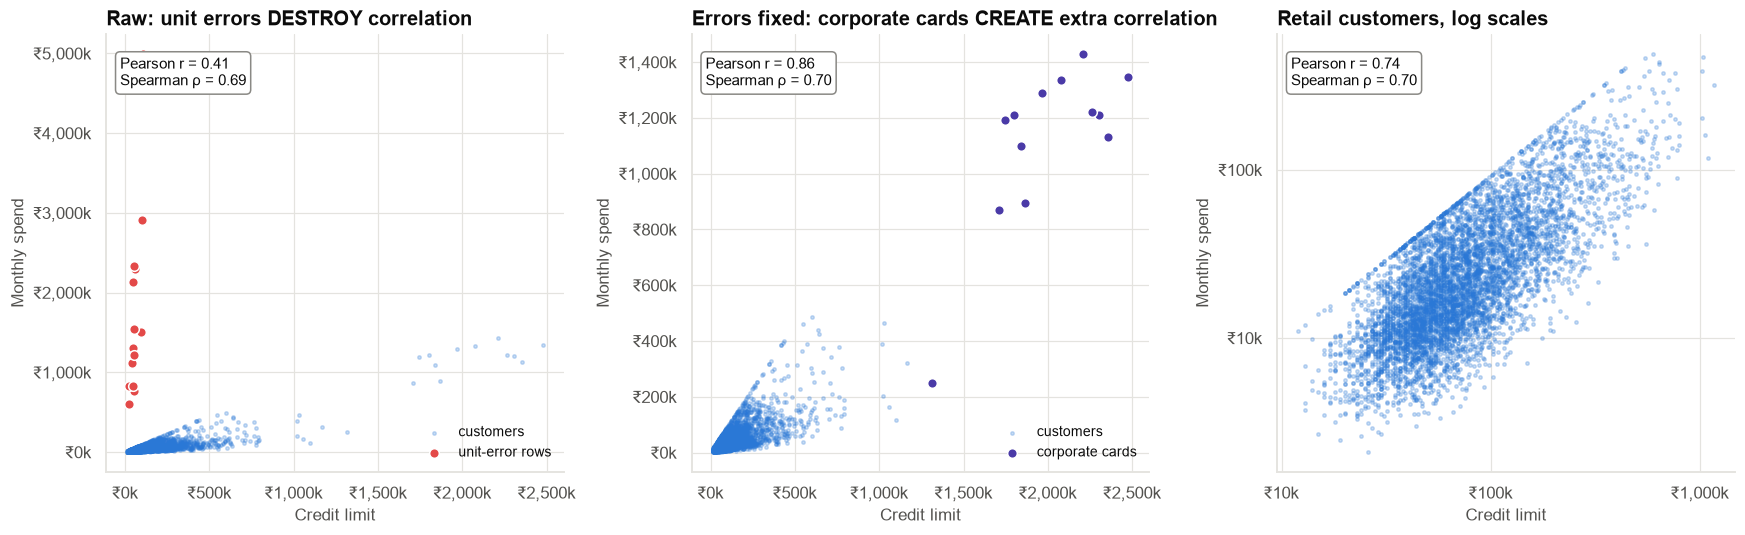

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
panels = [("Raw: unit errors DESTROY correlation", raw, raw["utilization"] > 1, COLORS["red"], "unit-error rows"),
          ("Errors fixed: corporate cards CREATE extra correlation", cards, cards["corporate_card"] == 1, COLORS["violet"], "corporate cards"),
          ("Retail customers, log scales", retail, None, None, None)]
for ax, (title, d, flag, fc, flab) in zip(axes, panels, strict=True):
    base = d if flag is None else d[~flag]
    ax.scatter(base["credit_limit"], base["monthly_spend"], s=5, alpha=0.25, color=PRIMARY, label="customers")
    if flag is not None:
        ax.scatter(d.loc[flag, "credit_limit"], d.loc[flag, "monthly_spend"], s=40, color=fc, edgecolor="white", label=flab, zorder=3)
    r = stats.pearsonr(d["credit_limit"], d["monthly_spend"])[0]
    rho = stats.spearmanr(d["credit_limit"], d["monthly_spend"])[0]
    if flag is None:
        ax.set_xscale("log"); ax.set_yscale("log")
        r = stats.pearsonr(np.log(d["credit_limit"]), np.log(d["monthly_spend"]))[0]
    ax.xaxis.set_major_formatter(kfmt); ax.yaxis.set_major_formatter(kfmt)
    ax.set(title=title, xlabel="Credit limit", ylabel="Monthly spend")
    ax.text(0.03, 0.95, f"Pearson r = {r:.2f}\nSpearman ρ = {rho:.2f}", transform=ax.transAxes, va="top", fontsize=10,
            bbox=dict(boxstyle="round", facecolor="white", edgecolor=INK_MUTED))
    if flag is not None:
        ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
save_fig(fig, "fig01_outliers_and_correlation", PATHS["figures"])
plt.show()

**Observation.** In the left panel, 15 points with absurd spend pull the cloud apart. In the middle, a dozen
corporate cards far to the upper right dominate the line. On log scales (right), the retail relationship is clearly
positive and roughly linear.

**Interpretation.** Pearson's r gives every point a weight proportional to its distance from the mean on both axes, so a
few extreme points can dominate it. Spearman ranks the data first, which caps each point's influence.

**Business implication.** Whether the dashboard says "0.4" or "0.86" depends on data errors and on a niche product,
not on the retail customers the proposal is about.

**Caveat.** Even the clean, robust correlation (≈ 0.7) says nothing yet about **why** limit and spend move together.

### 7.3 Is the correlation statistically significant? And is that the right question?

In [8]:
pairs = [("credit_limit", "monthly_spend"), ("monthly_income", "monthly_spend"), ("monthly_income", "credit_limit"),
         ("tenure_months", "monthly_spend"), ("age", "monthly_spend"), ("app_logins", "monthly_spend")]
sig_rows = []
for a, b in pairs:
    p_ = corr_ci(retail[a], retail[b]); s_ = corr_ci(retail[a], retail[b], "spearman")
    sig_rows.append({"pair": f"{a} ~ {b}", "Pearson r": p_["r"], "95% CI": f"[{p_['ci_low']:.3f}, {p_['ci_high']:.3f}]",
                     "p-value": fmt_p(p_["p_value"]), "r² (share of variance)": p_["r2"], "Spearman ρ": s_["r"]})
sig = pd.DataFrame(sig_rows).set_index("pair")
save_table(sig, "correlation_significance", PATHS["tables"])
sig

,Pearson r,95% CI,p-value,r² (share of variance),Spearman ρ
pair,,,,,
credit_limit ~ monthly_spend,0.730,"[0.718, 0.742]",< 0.001,0.533,0.698
monthly_income ~ monthly_spend,0.732,"[0.720, 0.744]",< 0.001,0.536,0.711
monthly_income ~ credit_limit,0.905,"[0.901, 0.910]",< 0.001,0.819,0.875
tenure_months ~ monthly_spend,0.021,"[-0.004, 0.046]",0.106,0.000,0.013
age ~ monthly_spend,0.042,"[0.016, 0.067]",0.001,0.002,0.076
app_logins ~ monthly_spend,-0.194,"[-0.218, -0.169]",< 0.001,0.038,-0.122


- **The test of a correlation** asks: if the true correlation were 0, how surprising is a sample r this far from 0?
  The test statistic is t = r·√(n−2)/√(1−r²) with n−2 degrees of freedom. The **CI** uses Fisher's z-transformation,
  z = arctanh(r), which is approximately normal with SE = 1/√(n−3).
- With n ≈ 6,000, **even a tiny correlation is "significant"**. Look at age: r ≈ 0.04 has p ≈ 0.001, yet r² says a
  straight line in age accounts for **0.2%** of the variation in spend. Statistically detectable, **practically
  negligible** as a linear effect (Case 22). Section 10 shows that age's real relationship is non-linear. Tenure
  (r ≈ 0.02, p ≈ 0.11) is not even detectable.
- Income, not the limit, has the strongest relationship with spend, and income and limit are correlated at about
  0.9 with each other. Hold on to that for Section 8.

> **Report r with its CI and r², not just a p-value.** With big data, the question is never "is r ≠ 0?" but "how big
> is it, and what does it mean?"

## Section 8 — Proposal 1: "Raise every limit by 30% to grow spend"

To act on this, the correlation would have to mean **"a higher limit causes higher spend"**. There are at least three
other explanations to rule out:

```text
(a) Confounding:      Income ──► Limit   and   Income ──► Spend   (limit and spend share a cause)
(b) Reverse causality: Spend ──► Limit   (the bank raises limits for customers who spend a lot)
(c) Real effect:       Limit ──► Spend   (only for customers whose limit stops them spending)
```

### 8.1 Confounding by income

In [9]:
r_ = retail.assign(log_income=np.log(retail["monthly_income"]), log_limit=np.log(retail["credit_limit"]),
                   log_spend=np.log(retail["monthly_spend"]))
res_spend = smf.ols("log_spend ~ log_income", r_).fit().resid
res_limit = smf.ols("log_limit ~ log_income", r_).fit().resid
partial = corr_ci(res_limit, res_spend)
raw_log = corr_ci(r_["log_limit"], r_["log_spend"])
print(f"Correlation of log limit and log spend:                     r = {raw_log['r']:.2f}  [{raw_log['ci_low']:.2f}, {raw_log['ci_high']:.2f}]")
print(f"PARTIAL correlation, removing log income from both:          r = {partial['r']:.2f}  [{partial['ci_low']:.2f}, {partial['ci_high']:.2f}]")
print(f"Correlation of log income with log limit: {corr_ci(r_['log_income'], r_['log_limit'])['r']:.2f};  "
      f"with log spend: {corr_ci(r_['log_income'], r_['log_spend'])['r']:.2f}")

r_["income_decile"] = pd.qcut(r_["monthly_income"], 10, labels=[f"D{i}" for i in range(1, 11)])
within = r_.groupby("income_decile", observed=True).apply(lambda g: pd.Series({"n": len(g), "r_within": stats.pearsonr(g["log_limit"], g["log_spend"])[0]}))
save_table(within, "limit_spend_within_income_deciles", PATHS["tables"])
within.T

Correlation of log limit and log spend:                     r = 0.74  [0.73, 0.75]
PARTIAL correlation, removing log income from both:          r = 0.23  [0.20, 0.25]
Correlation of log income with log limit: 0.90;  with log spend: 0.74


income_decile,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
n,602.000,604.000,596.000,600.000,598.000,592.000,601.000,596.000,600.000,598.000
r_within,0.316,0.243,0.266,0.244,0.205,0.241,0.188,0.215,0.353,0.524


**Partial correlation** answers: *among customers with the same income, do those with higher limits spend more?* We
remove income's linear effect from both variables (regress each on income, keep the residuals) and correlate what is
left.

The correlation falls from about 0.74 to about **0.2** once income is held fixed, and within narrow income bands
it is modest in most deciles. **Most of the limit–spend correlation exists because both depend on income.** The bank sets
limits from income, and richer people spend more.

### 8.2 Reverse causality: who gets higher limits?

In [10]:
rev = retail.groupby("limit_increase_12m").agg(customers=("customer_id", "size"), median_spend=("monthly_spend", "median"),
                                               median_income=("monthly_income", "median"), mean_utilization=("utilization", "mean"))
rev.index = rev.index.map({0: "no limit increase", 1: "limit increased in last 12m"})
save_table(rev, "limit_increase_profile", PATHS["tables"])
rev

,customers,median_spend,median_income,mean_utilization
limit_increase_12m,,,,
no limit increase,4403,"16,800.000","54,100.000",0.298
limit increased in last 12m,1584,"35,645.000","55,550.000",0.506


Customers whose limits were raised spend far more and use much more of their limit. That fits the bank's own
limit-increase programme, which **selects** customers who use their cards heavily. Part of "high limit ↔ high spend" is
**spend causing limit**, the opposite direction to the proposal.

### 8.3 Restriction of range: does the correlation hold within a narrow limit band?

In [11]:
band = retail[retail["credit_limit"].between(40_000, 60_000)]
rb = corr_ci(band["credit_limit"], band["monthly_spend"])
print(f"Within the ₹40–60k limit band (n = {len(band):,}): r = {rb['r']:.2f} [{rb['ci_low']:.2f}, {rb['ci_high']:.2f}]   "
      f"vs {corr_ci(retail['credit_limit'], retail['monthly_spend'])['r']:.2f} over the full range")

Within the ₹40–60k limit band (n = 1,574): r = 0.23 [0.18, 0.27]   vs 0.73 over the full range


**Restriction of range** cuts correlations: within a narrow band of limits, the limit varies little, so it cannot
"explain" much of the spread in spend. The reverse is also true: a correlation computed over a **wide** range (Mass to
Super-premium) can look impressive. Neither number is wrong. They answer different questions, and the range must
always be stated.

### 8.4 Who could actually respond to a higher limit?

In [12]:
near = retail["utilization"] >= 0.85
share_near = near.mean()
spend_share_near = retail.loc[near, "monthly_spend"].sum() / retail["monthly_spend"].sum()
max_uplift = spend_share_near * 0.30          # if EVERY near-limit customer used ALL of the extra 30%

x = np.log(retail["credit_limit"]); y = np.log(retail["monthly_spend"])
elasticity = np.polyfit(x, y, 1)[0]
naive_uplift = 1.30 ** elasticity - 1
print(f"Customers using ≥ 85% of their limit: {share_near:.1%}  (they account for {spend_share_near:.1%} of spend)")
print(f"Generous upper bound on uplift (all near-limit customers use the full extra 30%): +{max_uplift:.1%} of total spend")
print(f"'Correlation-as-causation' estimate (log-log slope {elasticity:.2f} applied to +30%):   +{naive_uplift:.0%} of total spend")

Customers using ≥ 85% of their limit: 4.9%  (they account for 11.5% of spend)
Generous upper bound on uplift (all near-limit customers use the full extra 30%): +3.4% of total spend
'Correlation-as-causation' estimate (log-log slope 0.90 applied to +30%):   +27% of total spend


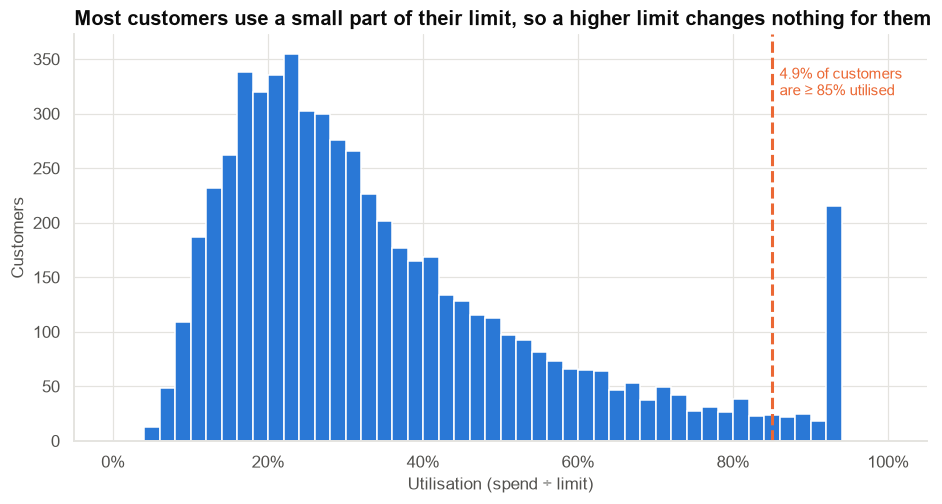

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.hist(retail["utilization"], bins=np.linspace(0, 1, 51), color=PRIMARY, edgecolor="white")
ax.axvline(0.85, color=HIGHLIGHT, lw=2, ls="--")
ax.text(0.86, ax.get_ylim()[1] * 0.85, f"{share_near:.1%} of customers\nare ≥ 85% utilised", color=HIGHLIGHT, fontsize=10)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(title="Most customers use a small part of their limit, so a higher limit changes nothing for them",
       xlabel="Utilisation (spend ÷ limit)", ylabel="Customers")
save_fig(fig, "fig02_utilisation_headroom", PATHS["figures"])
plt.show()

**This is the decisive argument against reading the correlation causally.** Most customers use 15–35% of their limit. The spike at about 92% is the minority who are spending up to their limit.
Their spending is not held back by the limit, so raising it cannot change their spend. Only the few customers near
their limit could spend more. Even if every one of them used the entire extra 30%, total spend would rise by a few
percent at most.

The naive reading ("spend rises with limit with a slope of about 0.9 on log scales, so +30% limits ⇒ about +27%
spend") is off by an order of magnitude.

### 8.5 Answer key: what would really happen? (teaching device)

Because the data is synthetic, we know each customer's unobservable "desired" spend, and therefore exactly what a
30% limit increase would do. A real analyst would have to run an experiment to learn this.

,uplift in total spend
naive (correlation read as causation),+26.7%
upper bound from headroom analysis,+3.4%
TRUE effect (answer key),+1.5%


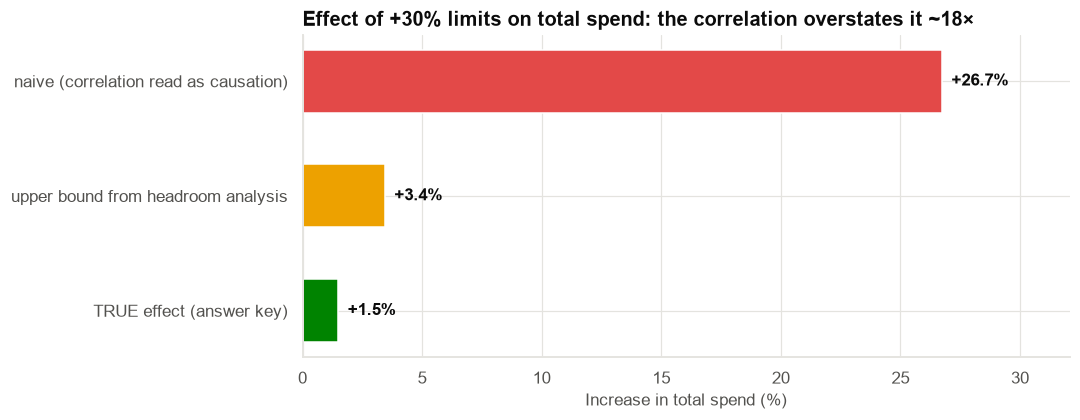

In [14]:
key = pd.read_csv(PATHS["data"] / "_answer_key_limit_effect.csv")
m = retail.merge(key, on="customer_id")
true_uplift = m["spend_if_limit_plus_30pct"].sum() / m["monthly_spend"].sum() - 1
comparison = pd.Series({"naive (correlation read as causation)": naive_uplift, "upper bound from headroom analysis": max_uplift,
                        "TRUE effect (answer key)": true_uplift}, name="uplift in total spend")
save_table(comparison.to_frame(), "limit_increase_uplift", PATHS["tables"])
display(comparison.to_frame().style.format("{:+.1%}"))

fig, ax = plt.subplots(figsize=(9, 3.8))
colors = [COLORS["red"], COLORS["yellow"], COLORS["green"]]
ax.barh(range(3), comparison.values * 100, color=colors, height=0.55)
for i, v in enumerate(comparison.values):
    ax.text(v * 100 + 0.4, i, f"+{v:.1%}", va="center", fontsize=11, fontweight="bold")
ax.set_yticks(range(3), comparison.index)
ax.invert_yaxis()
ax.set_xlim(0, comparison.max() * 100 * 1.2)
ax.set(title=f"Effect of +30% limits on total spend: the correlation overstates it ~{naive_uplift / true_uplift:.0f}×", xlabel="Increase in total spend (%)")
save_fig(fig, "fig03_naive_vs_true_effect", PATHS["figures"])
plt.show()

The true effect of a 30% limit increase is about **+1.5%** of spend, against roughly **+27%** implied by treating
the correlation as causal. It comes entirely from the small group of customers whose limit was actually binding.
Limit increases also raise **exposure and potential credit losses** on the whole book, so the proposal would add
risk on 100% of customers to gain spend from about 5% of them.

## Section 9 — Proposal 2: "Customers who log in more spend less"

In [15]:
pooled = corr_ci(retail["app_logins"], retail["monthly_spend"], "spearman")
seg_rows = [{"segment": "ALL (pooled)", "n": pooled["n"], "Spearman ρ": pooled["r"], "CI": f"[{pooled['ci_low']:.2f}, {pooled['ci_high']:.2f}]"}]
for s, g in retail.groupby("segment"):
    c = corr_ci(g["app_logins"], g["monthly_spend"], "spearman")
    seg_rows.append({"segment": s, "n": c["n"], "Spearman ρ": c["r"], "CI": f"[{c['ci_low']:.2f}, {c['ci_high']:.2f}]",
                     "median logins": g["app_logins"].median(), "median spend": g["monthly_spend"].median()})
logins = pd.DataFrame(seg_rows).set_index("segment")
save_table(logins, "logins_spend_by_segment", PATHS["tables"])
logins

,n,Spearman ρ,CI,median logins,median spend
segment,,,,,
ALL (pooled),5987,-0.122,"[-0.15, -0.10]",NaN,NaN
Mass,4196,0.585,"[0.56, 0.60]",23.000,"14,900.000"
Premium,1489,0.485,"[0.45, 0.52]",10.000,"38,830.000"
Super-premium,302,0.353,"[0.25, 0.45]",6.000,"104,750.000"


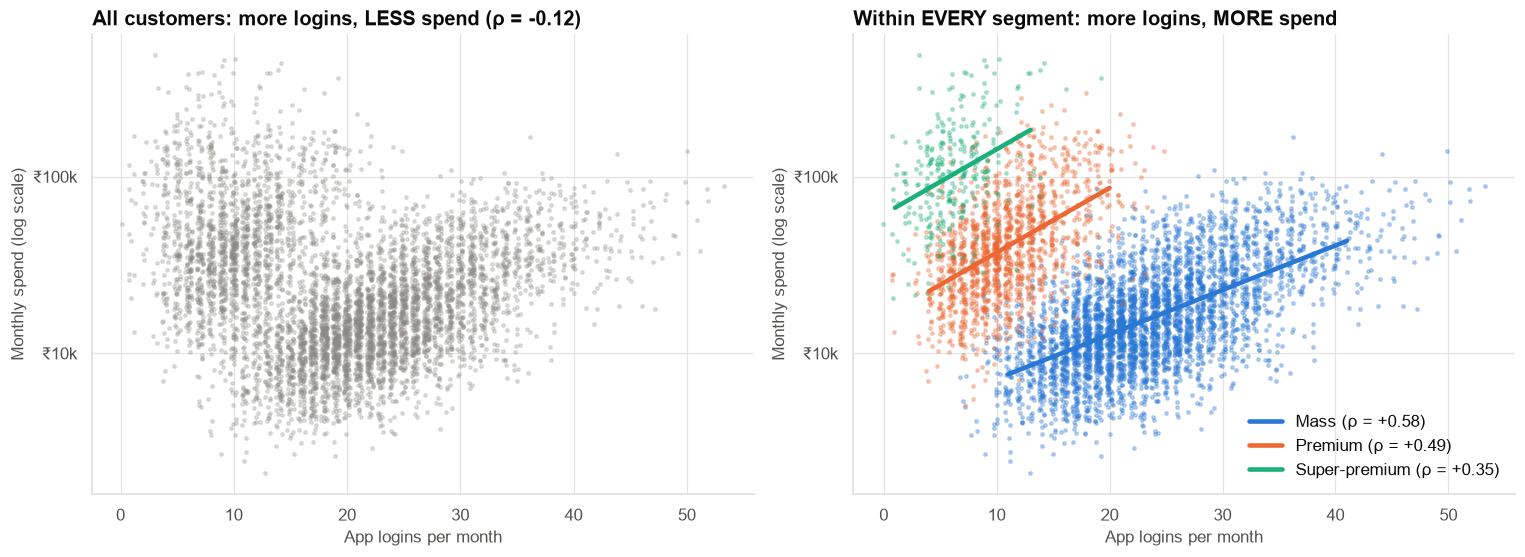

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
ax = axes[0]
ax.scatter(retail["app_logins"] + rng.uniform(-0.3, 0.3, len(retail)), retail["monthly_spend"], s=5, alpha=0.25, color=INK_MUTED)
ax.set_yscale("log"); ax.yaxis.set_major_formatter(kfmt)
ax.set(title=f"All customers: more logins, LESS spend (ρ = {pooled['r']:.2f})", xlabel="App logins per month", ylabel="Monthly spend (log scale)")
ax = axes[1]
for s, g in retail.groupby("segment"):
    ax.scatter(g["app_logins"] + rng.uniform(-0.3, 0.3, len(g)), g["monthly_spend"], s=5, alpha=0.3, color=SEG_COLORS[s])
    b = np.polyfit(g["app_logins"], np.log(g["monthly_spend"]), 1)
    xs = np.linspace(g["app_logins"].quantile(0.02), g["app_logins"].quantile(0.98), 20)
    ax.plot(xs, np.exp(np.polyval(b, xs)), color=SEG_COLORS[s], lw=3, label=f"{s} (ρ = {logins.loc[s, 'Spearman ρ']:+.2f})")
ax.set_yscale("log"); ax.yaxis.set_major_formatter(kfmt)
ax.set(title="Within EVERY segment: more logins, MORE spend", xlabel="App logins per month", ylabel="Monthly spend (log scale)")
ax.legend(loc="lower right")
fig.tight_layout()
save_fig(fig, "fig04_logins_reversal", PATHS["figures"])
plt.show()

**Observation.** Pooled, the correlation is negative. Within Mass, Premium and Super-premium separately, it is clearly
**positive**.

**Interpretation.** Mass customers log in far more often (they check balances and due dates) and spend far less than
Premium customers. Pooling segments mixes a **between-segment** pattern (Mass: many logins, low spend) with a
**within-segment** pattern (more engaged customers spend more). Segment is a confounder, and the pooled
correlation has the *opposite sign* to the within-segment one. This is Simpson's paradox for correlations (Case 20
covers the paradox for rates).

**Business implication.** The proposal to cut the app budget rests on the misleading pooled number. Within any
customer group, engaged users are the higher spenders.

**Caveat.** The within-segment correlation still does not prove that *pushing* logins would raise spend. It could be that
customers who spend more check the app more. To learn whether app campaigns *cause* spend, run a randomised campaign
with a holdout (Case 03).

## Section 10 — Proposal 3: "Age has zero correlation with spend"

In [17]:
pa = corr_ci(retail["age"], retail["monthly_spend"]); sa = corr_ci(retail["age"], retail["monthly_spend"], "spearman")
spend_rel = retail["monthly_spend"] / retail["monthly_income"]           # spend relative to income
lin = smf.ols("np.log(monthly_spend) ~ np.log(monthly_income) + age", retail).fit()
quad = smf.ols("np.log(monthly_spend) ~ np.log(monthly_income) + age + I(age**2)", retail).fit()
mi = mutual_info_regression(retail[["age"]], np.log(retail["monthly_spend"]), random_state=1)[0]
lr_stat = 2 * (quad.llf - lin.llf)
print(f"Pearson r(age, spend) = {pa['r']:.3f} [{pa['ci_low']:.3f}, {pa['ci_high']:.3f}],  Spearman ρ = {sa['r']:.3f}")
print(f"Mutual information(age; log spend) = {mi:.3f}")
print(f"Adding age² to a model of log spend: LR = {lr_stat:.0f} (df 1), p = {fmt_p(stats.chi2.sf(lr_stat, 1))};  "
      f"age² coefficient = {quad.params['I(age ** 2)']:.5f}")
peak = -quad.params["age"] / (2 * quad.params["I(age ** 2)"])
print(f"Implied age of peak spend (holding income fixed): {peak:.0f} years")

Pearson r(age, spend) = 0.042 [0.016, 0.067],  Spearman ρ = 0.076
Mutual information(age; log spend) = 0.061
Adding age² to a model of log spend: LR = 1120 (df 1), p = < 0.001;  age² coefficient = -0.00163
Implied age of peak spend (holding income fixed): 43 years


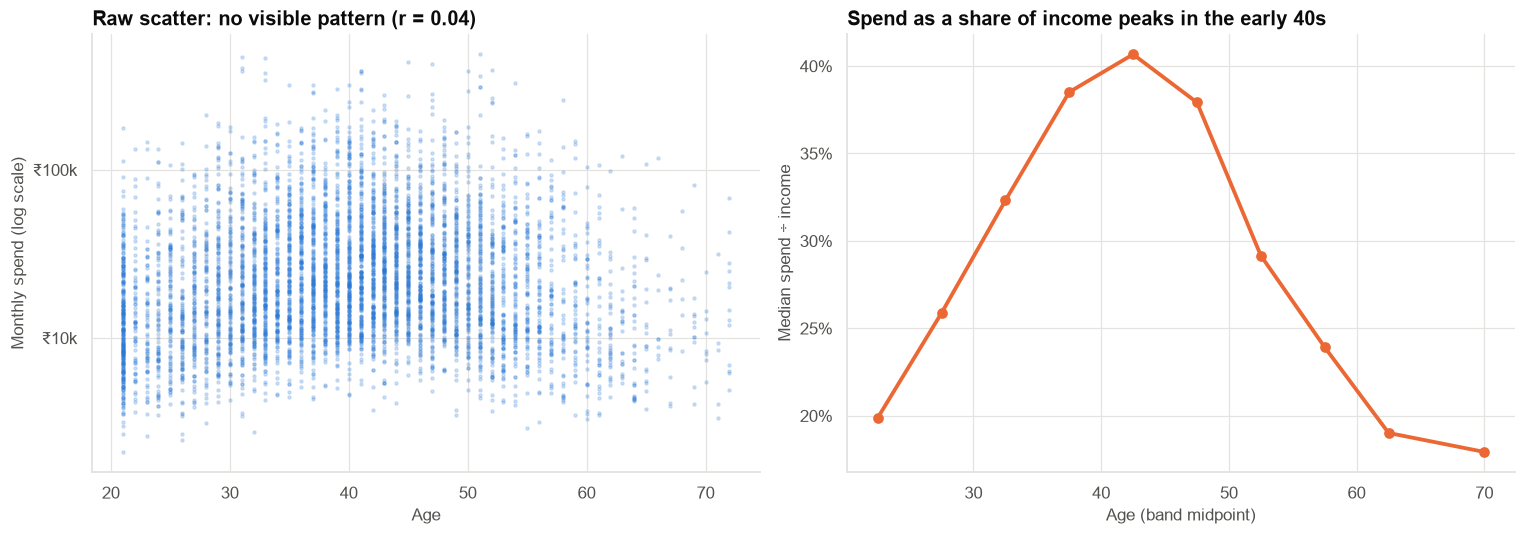

In [18]:
r_age = retail.assign(age_band=pd.cut(retail["age"], [20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 75]),
                      spend_to_income=retail["monthly_spend"] / retail["monthly_income"])
band_stats = r_age.groupby("age_band", observed=True)["spend_to_income"].agg(["median", "count"])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.scatter(retail["age"], retail["monthly_spend"], s=4, alpha=0.2, color=PRIMARY)
ax.set_yscale("log"); ax.yaxis.set_major_formatter(kfmt)
ax.set(title=f"Raw scatter: no visible pattern (r = {pa['r']:.2f})", xlabel="Age", ylabel="Monthly spend (log scale)")
ax = axes[1]
mids = [iv.mid for iv in band_stats.index]
ax.plot(mids, band_stats["median"], marker="o", lw=2.5, color=HIGHLIGHT)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(title="Spend as a share of income peaks in the early 40s", xlabel="Age (band midpoint)", ylabel="Median spend ÷ income")
fig.tight_layout()
save_fig(fig, "fig05_age_inverted_u", PATHS["figures"])
plt.show()

**Observation.** Pearson's r between age and spend is about zero. Yet customers in their early forties spend a much
larger share of their income on the card than customers in their twenties or sixties.

**Interpretation.** The relationship is an **inverted U**. Spend rises with age up to the early 40s and then falls. The
upward and downward halves cancel in a straight-line measure. Spearman cannot detect it either, because it is not
monotone. A quadratic term (likelihood-ratio test), a binned plot or mutual information all reveal it. Income also
masks it in the raw scatter, which is why we look at spend relative to income.

**Business implication.** "Stop age-based targeting" would discard a real pattern. Mid-career customers are the
highest-propensity spenders.

**Caveat.** As always, this is an association. Age is a proxy for life stage (family, housing, travel), which is what
targeting should really use.

> **Zero correlation ≠ no relationship.** It means **no linear relationship**. Always plot the data.

## Section 11 — Bonus: "Marketing spend and card spend correlate at 0.91"

Correlation of LEVELS (36 months):             r = 0.91 [0.84, 0.96], p = < 0.001
Correlation of MONTH-ON-MONTH CHANGES (35):     r = 0.17 [-0.17, 0.48], p = 0.323


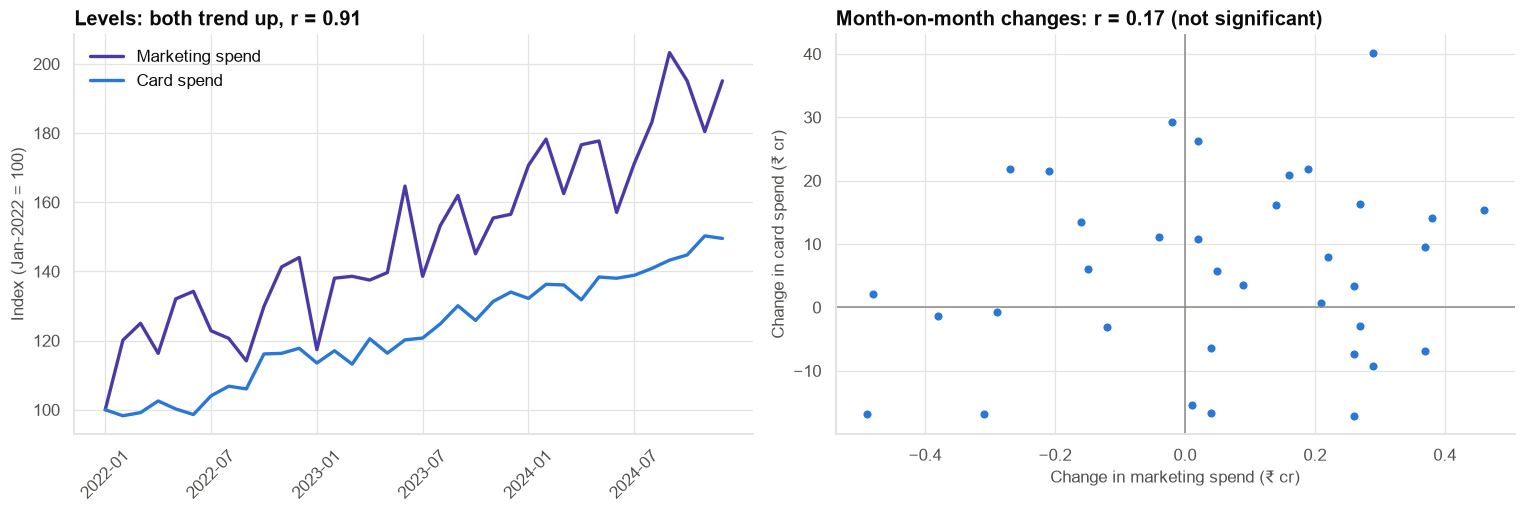

In [19]:
lv = corr_ci(ts["marketing_spend_cr"], ts["card_spend_cr"])
d_m, d_c = ts["marketing_spend_cr"].diff().dropna(), ts["card_spend_cr"].diff().dropna()
df_ = corr_ci(d_m, d_c)
print(f"Correlation of LEVELS (36 months):             r = {lv['r']:.2f} [{lv['ci_low']:.2f}, {lv['ci_high']:.2f}], p = {fmt_p(lv['p_value'])}")
print(f"Correlation of MONTH-ON-MONTH CHANGES (35):     r = {df_['r']:.2f} [{df_['ci_low']:.2f}, {df_['ci_high']:.2f}], p = {fmt_p(df_['p_value'])}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
ax.plot(ts["month"], ts["marketing_spend_cr"] / ts["marketing_spend_cr"].iloc[0] * 100, color=COLORS["violet"], lw=2.2, label="Marketing spend")
ax.plot(ts["month"], ts["card_spend_cr"] / ts["card_spend_cr"].iloc[0] * 100, color=PRIMARY, lw=2.2, label="Card spend")
ax.set_xticks(ts["month"][::6])
ax.tick_params(axis="x", rotation=45)
ax.set(title=f"Levels: both trend up, r = {lv['r']:.2f}", ylabel="Index (Jan-2022 = 100)")
ax.legend(loc="upper left")
ax = axes[1]
ax.scatter(d_m, d_c, color=PRIMARY, s=40, edgecolor="white")
ax.axhline(0, color=INK_MUTED, lw=1); ax.axvline(0, color=INK_MUTED, lw=1)
ax.set(title=f"Month-on-month changes: r = {df_['r']:.2f} (not significant)", xlabel="Change in marketing spend (₹ cr)",
       ylabel="Change in card spend (₹ cr)")
fig.tight_layout()
save_fig(fig, "fig06_spurious_time_series", PATHS["figures"])
plt.show()

Any two series that both grow over time (the business is growing, prices rise) will show a high correlation in
**levels**, whether or not one affects the other. This is a **spurious correlation**. The informative question is whether
months with *unusually high* marketing are followed by *unusually high* card spend. That is what correlating the
**changes** (or de-trended series) asks. Here the answer is no clear relationship (r ≈ 0.2, CI spanning zero).

Also note: consecutive months are **not independent observations** (autocorrelation), so the p-value for the levels
correlation is badly overstated. Standard correlation tests assume independent observations. Case 25 covers time
series properly.

## Section 12 — Assumption checks for correlation analysis

| Assumption | Why it matters | Check here |
|---|---|---|
| **Independent observations** | Tests and CIs assume it | ✅ customers; ❌ monthly series (autocorrelated): use changes |
| **Linearity** (Pearson) | r measures only straight-line association | ❌ age; ✅ log limit vs log spend |
| **No undue influence from outliers** (Pearson) | A few points can dominate | Compared Pearson vs Spearman, with/without outliers |
| **Approx. bivariate normality** (Pearson CI/test) | Fisher-z CI relies on it | Use logs for money variables; Spearman otherwise |
| **Homogeneous population** | Mixing groups can create or reverse correlations | Checked within segments and income bands |
| **Adequate range** | Restricted range shrinks r | Stated the range for every correlation |

## Section 13 — Results

In [20]:
results = pd.DataFrame([
    ["Limit ~ spend, Pearson (raw → retail)", f"{limit_corrs['Pearson r'].iloc[0]:.2f} → {limit_corrs['Pearson r'].iloc[2]:.2f}", "outliers move Pearson a lot"],
    ["Limit ~ spend, Spearman (all versions)", f"{limit_corrs['Spearman ρ'].min():.2f}–{limit_corrs['Spearman ρ'].max():.2f}", "robust"],
    ["Limit ~ spend, partial r given income (logs)", f"{partial['r']:.2f} [{partial['ci_low']:.2f}, {partial['ci_high']:.2f}]", "mostly confounded by income"],
    ["Customers ≥ 85% utilised", f"{share_near:.1%}", "only they can respond to a higher limit"],
    ["+30% limits: naive vs true uplift", f"+{naive_uplift:.0%} vs +{true_uplift:.1%}", "correlation ≠ causal effect"],
    ["Logins ~ spend, pooled vs within segments", f"{pooled['r']:+.2f} vs {logins['Spearman ρ'].iloc[1:].min():+.2f} to {logins['Spearman ρ'].iloc[1:].max():+.2f}", "reversal"],
    ["Age ~ spend, Pearson; age² LRT p", f"{pa['r']:.2f}; {fmt_p(stats.chi2.sf(lr_stat, 1))}", "inverted U"],
    ["Marketing ~ card spend, levels vs changes", f"{lv['r']:.2f} vs {df_['r']:.2f}", "spurious trend correlation"],
], columns=["finding", "value", "meaning"]).set_index("finding")
save_table(results, "key_results", PATHS["tables"])
results

,value,meaning
finding,,
"Limit ~ spend, Pearson (raw → retail)",0.41 → 0.73,outliers move Pearson a lot
"Limit ~ spend, Spearman (all versions)",0.69–0.70,robust
"Limit ~ spend, partial r given income (logs)","0.23 [0.20, 0.25]",mostly confounded by income
Customers ≥ 85% utilised,4.9%,only they can respond to a higher limit
+30% limits: naive vs true uplift,+27% vs +1.5%,correlation ≠ causal effect
"Logins ~ spend, pooled vs within segments",-0.12 vs +0.35 to +0.58,reversal
"Age ~ spend, Pearson; age² LRT p",0.04; < 0.001,inverted U
"Marketing ~ card spend, levels vs changes",0.91 vs 0.17,spurious trend correlation


## Section 14 — Interpretation

**Proposal 1 (raise limits).** Among retail customers, limit and spend are strongly associated (Spearman ρ ≈ 0.70;
Pearson on logs ≈ 0.74). The dashboard's number swings between about 0.4 and 0.86 depending on 15 data errors and 12
corporate cards. But the association is mostly **not** a limit effect: once income is held constant the correlation
drops to about 0.2, customers who received limit increases were already heavy spenders (reverse causality), and only
about 5% of customers are close enough to their limit for it to constrain them. Read causally, the correlation predicts
about +27% spend from +30% limits. The true effect (answer key) is about **+1.5%**.

**Proposal 2 (cut the app).** The pooled correlation between logins and spend is negative only because Mass customers
log in more and spend less. **Within every segment the correlation is positive** (ρ ≈ +0.35 to +0.6).

**Proposal 3 (drop age).** Age's correlation with spend is about zero because the relationship is an **inverted U**
peaking in the early 40s. A likelihood-ratio test for a quadratic term is overwhelmingly significant.

**Bonus (marketing).** A 0.91 correlation between two upward-trending series is spurious. Month-to-month changes are
not clearly related.

## Section 15 — What can we say?

### ✅ We can confidently say
- Credit limit and spend are positively **associated** among retail customers, and the association is strong when
  measured robustly.
- The dashboard's limit–spend correlation is distorted by data errors and corporate cards.
- Within each segment, customers who use the app more spend more (**association**).
- Spend relative to income peaks in the early 40s. Age matters, non-linearly.

### 📊 We have evidence that
- Most of the limit–spend association is explained by income (confounding) and by limit increases going to heavy
  spenders (reverse causality).
- Only a small minority of customers are limit-constrained, so a blanket limit increase would change little.

### ❌ We cannot conclude
- That raising limits **causes** a meaningful spend increase. The evidence points the other way.
- That app engagement **causes** spend (it may be the reverse).
- That marketing spend drives card spend, from a correlation of levels.

### 🔍 We would need additional analysis or data to conclude
- A **randomised limit-increase test** on near-limit customers to measure the real effect and its credit-risk cost.
- A **randomised app-engagement campaign** with a holdout.
- A proper **time-series / marketing-mix analysis** (lags, seasonality, controls) for marketing.

## Section 16 — Business interpretation

| Statistical finding | Data scientist interpretation | Business interpretation | Business action |
|---|---|---|---|
| Pearson 0.4–0.86 vs Spearman ≈ 0.7 | Pearson driven by 27 unusual rows | The dashboard number is unreliable | Fix the unit error; report corporate cards separately; use robust measures |
| Partial r ≈ 0.2 given income; increases went to heavy spenders | Confounding + reverse causality | Limits don't drive spend for most customers | **Do not raise all limits** |
| ~5% near limit; true uplift ≈ +1.5% vs naive +27% | Limit binds for few | Blanket increase adds risk on 100% of the book for little spend | Targeted, risk-assessed increases for near-limit customers, tested first |
| Logins ↔ spend negative pooled, positive in every segment | Segment confounding | App users are the better spenders within each group | **Don't cut the app budget**; test app campaigns with holdouts |
| Age r ≈ 0 but inverted U (LRT p < 0.001) | Non-linear relationship | Mid-career customers spend most | Keep life-stage targeting |
| Levels r = 0.91, changes r ≈ 0.2 (ns) | Spurious trend correlation | No evidence marketing drives spend from this | Commission a proper marketing-mix analysis |

## Section 17 — Limitations

- Cross-sectional data: averages over 6 months, one point in time.
- Answer key exists only because the data is synthetic. In reality the true limit effect must be measured
  experimentally.
- Engagement is measured only by logins.
- Monthly series has only 36 points.
- **Synthetic data.**

## Section 18 — Final recommendation

1. **Do not approve a blanket 30% limit increase.** The correlation behind it is mostly confounding and reverse
   causality. The real spend gain would be small (≈ 1–2%), and the added exposure would apply to the whole book.
2. Instead, **run a randomised limit-increase test** for customers who are near their limit and meet risk criteria,
   measuring both spend and losses.
3. **Do not cut app investment.** Within each segment, engaged customers spend more. Test engagement campaigns with
   holdouts.
4. **Keep age/life-stage targeting.**
5. **Fix the dashboard:** correct the unit error, separate corporate cards, show Spearman and scatter plots alongside
   any correlation, and stop correlating trending series in levels.

## Section 19 — What would I do next?

- Design the limit-increase experiment: sample size for detecting a spend uplift and a loss-rate change (Case 04).
- Model spend with income, age (non-linear), segment and engagement (Cases 06–08) to separate effects.
- Marketing-mix model with lags and seasonality for the marketing question (Case 25).

---

### Concepts covered
Pearson r · Spearman ρ · Kendall τ · r² · Fisher-z confidence interval · significance test for r · outliers that create /
destroy correlation · log transformation · confounding and partial correlation · reverse causality · restriction of
range · aggregation reversal (Simpson's paradox for correlations) · non-linear (non-monotone) relationships · mutual
information · quadratic term and likelihood-ratio test · spurious correlation of trending series · autocorrelation ·
association vs causation language.

### Exercises
1. Compute the limit–spend correlation **within** the near-limit group only. What do you expect, and why?
2. Compute Kendall's τ for logins vs spend in the Mass segment and compare it with Spearman's ρ.
3. De-trend both monthly series with a linear trend (instead of differencing) and re-compute the correlation.
4. Write one sentence each for proposals 1–3 that a careful analyst could put in an Executive Committee paper.